# 4.3 CNN EfficientNet-B0 (Fine-Tuning total) : Dataset 2 (extrait final, 60 000 images)

EfficientNet-B0 pré-entraîné sur ImageNet, dernière couche remplacée par 6 classes, tout le réseau
ré-entraîné (Fine-Tuning total). On suit les étapes du cours PyTorch.

- images en 384 × 384 (en 224 le texte devient illisible) ;
- petite augmentation (rotation, luminosité, contraste), jamais de retournement ;
- 10 epochs au plus, early stopping sur 10 % du train.

L'entraînement prend environ 46 minutes : s'il a déjà été fait, on recharge le modèle enregistré.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")  # avertissement tqdm sans importance

import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import timm
import torch
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import StratifiedKFold, train_test_split
from torch import nn, optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from outils_4 import ARTEFACTS_60K, ARTEFACTS_DATASET_1, CLASSES, load_corpus_60k, save_probas

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
MODELE = f"{ARTEFACTS_60K}/etape5_cnn_model.pt"
HISTORIQUE = f"{ARTEFACTS_60K}/cnn_historique.csv"

train, test = load_corpus_60k()
train_sous, validation = train_test_split(train, test_size=0.1, random_state=42, stratify=train["label"])
print(f"Entraînement : {len(train_sous)} | Validation : {len(validation)} | Test : {len(test)} | Appareil : {device}")

Entraînement : 8614 | Validation : 958 | Test : 2394 | Appareil : mps


## 1. Les images : `transforms`, `ImageFolder`, `DataLoader`

In [2]:
normalisation = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # comme ImageNet
transform_train = transforms.Compose([transforms.Resize((384, 384)),
                                      transforms.RandomRotation(degrees=3),
                                      transforms.ColorJitter(brightness=0.15, contrast=0.15),
                                      transforms.ToTensor(), normalisation])
transform_eval = transforms.Compose([transforms.Resize((384, 384)), transforms.ToTensor(), normalisation])

# ImageFolder lit tout le dossier, on ne garde ensuite que nos documents
images_train = datasets.ImageFolder("../data/rvl_cdip_filtered_dataset_3", transform=transform_train)
images_eval = datasets.ImageFolder("../data/rvl_cdip_filtered_dataset_3", transform=transform_eval)
assert images_eval.classes == CLASSES


def make_loader(df, images, shuffle=False):
    """DataLoader sur les documents de df, dans le même ordre"""
    position = {chemin: i for i, (chemin, _) in enumerate(images.samples)}
    return DataLoader(Subset(images, [position["../" + f] for f in df["filepath"]]), batch_size=32, shuffle=shuffle)

## 2. Le modèle, la fonction de perte, l'optimiseur

`timm` fournit le modèle pré-entraîné, comme `torchvision.models` dans le cours. Les couches déjà
entraînées apprennent 10 fois moins vite que la nouvelle.

In [3]:
torch.manual_seed(42)
model = timm.create_model("efficientnet_b0", pretrained=not os.path.exists(MODELE), num_classes=6).to(device)

criterion = nn.CrossEntropyLoss()
derniere_couche = list(model.get_classifier().parameters())
ids_derniere_couche = {id(p) for p in derniere_couche}
couches_pre_entrainees = [p for p in model.parameters() if id(p) not in ids_derniere_couche]
optimizer = optim.AdamW([{"params": couches_pre_entrainees, "lr": 1e-4},
                         {"params": derniere_couche, "lr": 1e-3}])
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)  # le lr baisse à chaque epoch

## 3. Entraînement

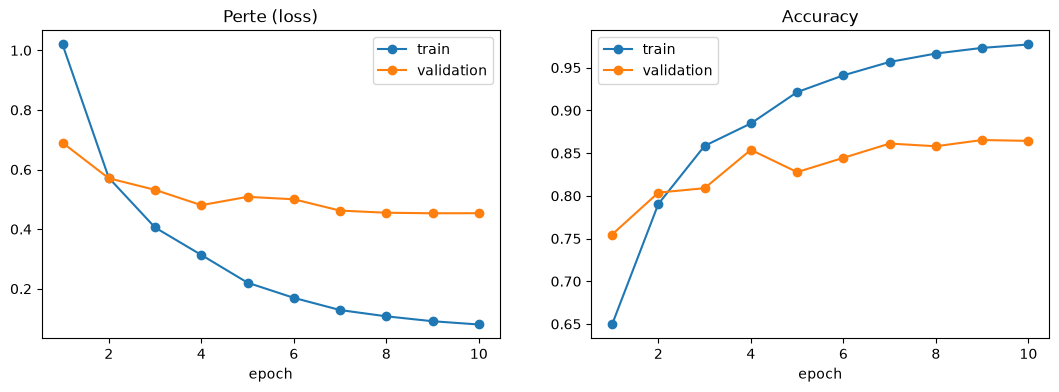

In [4]:
if os.path.exists(MODELE):
    model.load_state_dict(torch.load(MODELE, map_location=device))
    historique = pd.read_csv(HISTORIQUE)
else:
    dataloader_train = make_loader(train_sous, images_train, shuffle=True)
    dataloader_val = make_loader(validation, images_eval)
    historique, meilleure_acc, sans_progres = [], 0, 0
    for epoch in range(10):
        model.train()
        loss_total, bons = 0, 0
        for X_batch, y_batch in dataloader_train:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            loss.backward()
            optimizer.step()
            loss_total += loss.item() * len(y_batch)
            bons += (y_pred.argmax(dim=1) == y_batch).sum().item()

        model.eval()
        val_loss, val_bons = 0, 0
        with torch.no_grad():
            for X_val, y_val in dataloader_val:
                X_val, y_val = X_val.to(device), y_val.to(device)
                sorties = model(X_val)
                val_loss += criterion(sorties, y_val).item() * len(y_val)
                val_bons += (sorties.argmax(dim=1) == y_val).sum().item()
        scheduler.step()

        historique.append({"epoch": epoch + 1, "train_loss": loss_total / len(train_sous), "train_acc": bons / len(train_sous),
                           "val_loss": val_loss / len(validation), "val_acc": val_bons / len(validation)})
        print(f"Epoch {epoch + 1}/10, train : {historique[-1]['train_acc']:.1%} | validation : {historique[-1]['val_acc']:.1%}")

        # early stopping : on garde la meilleure epoch, arrêt après 3 epochs sans progrès
        if historique[-1]["val_acc"] > meilleure_acc:
            meilleure_acc, sans_progres = historique[-1]["val_acc"], 0
            torch.save(model.state_dict(), MODELE)
        else:
            sans_progres += 1
            if sans_progres == 3:
                break
    model.load_state_dict(torch.load(MODELE, map_location=device))
    historique = pd.DataFrame(historique)
    historique.to_csv(HISTORIQUE, index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, mesure, titre in [(axes[0], "loss", "Perte (loss)"), (axes[1], "acc", "Accuracy")]:
    ax.plot(historique["epoch"], historique[f"train_{mesure}"], marker="o", label="train")
    ax.plot(historique["epoch"], historique[f"val_{mesure}"], marker="o", label="validation")
    ax.set_xlabel("epoch")
    ax.set_title(titre)
    ax.legend()
plt.show()

Le train monte vers 98 %, la validation plafonne vers 86 % : début de surapprentissage. On garde la
meilleure epoch.

## 4. Évaluation sur le test

Accuracy test : 85.1%
                   precision    recall  f1-score   support

            email      0.963     0.965     0.964       400
             form      0.781     0.815     0.798       399
          invoice      0.879     0.835     0.856       399
     presentation      0.825     0.839     0.832       398
           resume      0.922     0.917     0.920       400
scientific_report      0.739     0.734     0.736       398

         accuracy                          0.851      2394
        macro avg      0.851     0.851     0.851      2394
     weighted avg      0.852     0.851     0.851      2394



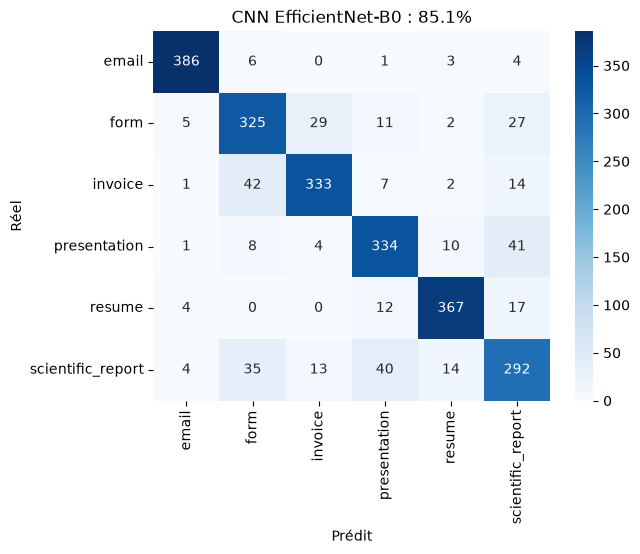

In [5]:
def predict_probas(model, df, images):
    model.eval()
    probas = []
    with torch.no_grad():
        for X_batch, _ in make_loader(df, images):
            probas.append(torch.softmax(model(X_batch.to(device)), dim=1).cpu().numpy())
    return np.concatenate(probas)


probas_test = predict_probas(model, test, images_eval)
y_pred = np.array(CLASSES)[probas_test.argmax(axis=1)]
print(f"Accuracy test : {accuracy_score(test['label'], y_pred):.1%}")
print(classification_report(test["label"], y_pred, digits=3))

matrice = pd.crosstab(test["label"], y_pred, rownames=["Réel"], colnames=["Prédit"])
sns.heatmap(matrice, annot=True, fmt="d", cmap="Blues")
plt.title(f"CNN EfficientNet-B0 : {accuracy_score(test['label'], y_pred):.1%}")
plt.show()

## 5. Probabilités enregistrées pour le stacking (4.5.3)

Sur le test, sur le dataset 1, et sur le train par validation croisée (3 plis de 8 epochs, environ
1 h 20, seulement si le fichier n'existe pas).

In [6]:
save_probas(f"{ARTEFACTS_60K}/probas_cnn_test.parquet", test["filepath"], probas_test)

dataset_1 = pd.read_csv(f"{ARTEFACTS_DATASET_1}/ocr_corpus.csv", keep_default_na=False)
images_dataset_1 = datasets.ImageFolder("../data/document-classification-dataset_1", transform=transform_eval)
save_probas(f"{ARTEFACTS_DATASET_1}/probas_cnn.parquet", dataset_1["filepath"],
            predict_probas(model, dataset_1, images_dataset_1))

if not os.path.exists(f"{ARTEFACTS_60K}/probas_cnn_oof.parquet"):
    probas_oof = np.zeros((len(train), len(CLASSES)))
    for idx_fit, idx_pli in StratifiedKFold(n_splits=3, shuffle=True, random_state=42).split(train, train["label"]):
        torch.manual_seed(42)
        cnn_pli = timm.create_model("efficientnet_b0", pretrained=True, num_classes=6).to(device)
        tete = list(cnn_pli.get_classifier().parameters())
        reste = [p for p in cnn_pli.parameters() if id(p) not in {id(q) for q in tete}]
        optimizer_pli = optim.AdamW([{"params": reste, "lr": 1e-4}, {"params": tete, "lr": 1e-3}])
        scheduler_pli = optim.lr_scheduler.CosineAnnealingLR(optimizer_pli, T_max=8)
        for epoch in range(8):
            cnn_pli.train()
            for X_batch, y_batch in make_loader(train.iloc[idx_fit], images_train, shuffle=True):
                optimizer_pli.zero_grad()
                loss = criterion(cnn_pli(X_batch.to(device)), y_batch.to(device))
                loss.backward()
                optimizer_pli.step()
            scheduler_pli.step()
        probas_oof[idx_pli] = predict_probas(cnn_pli, train.iloc[idx_pli], images_eval)
    save_probas(f"{ARTEFACTS_60K}/probas_cnn_oof.parquet", train["filepath"], probas_oof)
print("Probabilités du CNN enregistrées.")

Probabilités du CNN enregistrées.
